![image.png](https://i.imgur.com/a3uAqnb.png)

# NLP Tasks and Tokenizers in English and Arabic

- **Dataset**: [OPUS-100](https://huggingface.co/datasets/Helsinki-NLP/opus-100) from Hugging Face, the English-Arabic portion: 1,000,000 training and 2,000 test sentence pairs
- **Task**: run the main NLP task types on English and Arabic, then measure and train tokenizers
- **Model**: pretrained classifiers, taggers, a question-answering model, a translation model and a small instruction-tuned LLM (all used as they are); byte-level BPE tokenizers trained in the notebook
- **Runtime**: Colab T4 GPU, about 15 minutes of downloads and compute

In this lab, we will:

- run one model for each output shape: a label per text, a label per token, a span from a passage, and new text
- score two translation systems against reference translations with chrF
- count how six real tokenizers split the same English and Arabic sentences, and measure the Arabic token premium
- train our own BPE tokenizers and see how the training data and the vocabulary size change the token counts

## Task shapes and tokens in brief

Every NLP task maps text to one of four output shapes: one label for the whole text (classification), one label per token (sequence labeling, such as named entity recognition), a span copied from a given passage (extractive question answering), or new text (translation, summarization, open answers).

Before any model sees text, a **tokenizer** cuts it into tokens from a fixed vocabulary. Two numbers describe how a tokenizer treats a language:

$$\text{fertility} = \frac{\text{number of tokens}}{\text{number of words}} \qquad\qquad \text{premium} = \frac{\text{tokens for the Arabic sentences}}{\text{tokens for their English translations}}$$

Where:
- words are counted by splitting on whitespace
- the premium compares the same content in two languages, so it measures what a speaker of each language pays in tokens, and therefore in cost, speed and context

Paper: [Petrov et al., 2023. Language Model Tokenizers Introduce Unfairness Between Languages](https://arxiv.org/abs/2305.15425)

## Setup

In Google Colab, select **Runtime > Change runtime type > T4 GPU**, then run the cells from top to bottom. `sacrebleu` provides the chrF translation metric; everything else ships with Colab.

In [1]:
%pip install -q sacrebleu

In [2]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sacrebleu
from datasets import load_dataset
from tokenizers import Tokenizer, decoders, models, pre_tokenizers, trainers
from tqdm.auto import tqdm
from transformers import (AutoModelForCausalLM, AutoModelForQuestionAnswering, AutoModelForSeq2SeqLM,
                          AutoTokenizer, pipeline)

import torch
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()   # hide informational warnings from model loading and generation

Every size and model name lives in the next cell. `N_PAIRS` sets how many test sentence pairs are used for measuring tokenizers, `N_TRAIN_SENTENCES` how many sentences our own tokenizers are trained on, and `N_TRANSLATE` how many sentences each translation system translates.

In [3]:
SEED = 42
N_PAIRS = 1_000             # test pairs for measuring tokenizers (filtered by length below)
N_TRAIN_SENTENCES = 40_000  # sentences per language for training our BPE tokenizers
N_TRANSLATE = 64            # sentences each translation system translates
BATCH_SIZE = 16             # sentences per generation batch
MAX_NEW_TOKENS = 96         # longest translation we let a model write
VOCAB_SIZES = [1_000, 4_000, 16_000, 32_000]

CLS_EN = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
CLS_AR = "CAMeL-Lab/bert-base-arabic-camelbert-mix-sentiment"
NER_EN = "dslim/bert-base-NER"
NER_AR = "CAMeL-Lab/bert-base-arabic-camelbert-mix-ner"
QA_MODEL = "deepset/xlm-roberta-base-squad2"
MT_MODEL = "Helsinki-NLP/opus-mt-en-ar"
LLM = "Qwen/Qwen2.5-1.5B-Instruct"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} | device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)} "
          f"({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB)")
else:
    print("No GPU found, so generation will be slow. In Colab: Runtime > Change runtime type > T4 GPU.")
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
PIPE_DEVICE = 0 if DEVICE == "cuda" else -1

PyTorch 2.14.1+cu130 | device: cuda
GPU: Tesla T4 (15.6 GB)


## 1. Dataset

- **Source**: [Helsinki-NLP/opus-100](https://huggingface.co/datasets/Helsinki-NLP/opus-100), configuration `ar-en` (Zhang et al., 2020)
- **Content**: English-Arabic sentence pairs sampled from the OPUS collection of parallel corpora: 1,000,000 training, 2,000 validation and 2,000 test pairs
- **Licence**: not stated on the dataset card
- **What we use**: test pairs whose English side has 8 to 40 words, for measuring tokenizers and translation; training sentences for our own tokenizers

Parallel text is what makes a fair comparison possible: each Arabic sentence has the same content as its English partner.

In [4]:
opus = load_dataset("Helsinki-NLP/opus-100", "ar-en")
print(opus)

def keep(pair):
    """Sentence pairs of ordinary length; very short ones are mostly menu items and labels."""
    return 8 <= len(pair["en"].split()) <= 40 and len(pair["ar"].split()) >= 4

test_pairs = [p["translation"] for p in opus["test"]]
test_pairs = [p for p in test_pairs if keep(p)][:N_PAIRS]
train_rows = opus["train"].shuffle(seed=SEED).select(range(4 * N_TRAIN_SENTENCES))
train_pairs = [p for p in train_rows["translation"] if keep(p)][:N_TRAIN_SENTENCES]
train_en = [p["en"] for p in train_pairs]
train_ar = [p["ar"] for p in train_pairs]
print(f"{len(test_pairs)} test pairs and {len(train_pairs)} training pairs after filtering")
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(test_pairs[:5])

README.md:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

ar-en/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  214kB            

ar-en/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ar-en/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 99.3MB            

ar-en/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ar-en/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  979kB            

... (2 outputs left out)

Generating train split:   0%|          | 0/1000000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['translation'],
        num_rows: 2000
    })
    train: Dataset({
        features: ['translation'],
        num_rows: 1000000
    })
    validation: Dataset({
        features: ['translation'],
        num_rows: 2000
    })
})
902 test pairs and 40000 training pairs after filtering


,ar,en
0,حسناً ، تبعاً للتقرير هناك ثلاث عبوات ماء مفقودة,"Well, according to the report, there were three water bottles missing."
1,81 - استعرضت اللجنة البيانات التي طلبتها من المؤسسات عن صعوبات التوظيف والاستبقاء.,"The Commission reviewed the data on recruitment and retention difficulties, which it had requested from the organiza..."
2,هل سترجع للعيش معنا هنا,"(Maya) So Are You Gonna Move Back In,"
3,وينبغي ألا تقدم التصويبات إلا للنص باللغات الأصلية.,Corrections should be submitted to the original languages only.
4,...لديّ الكثير، لذا إذا أردتي أن تُـحضِري أصدقاء، إفعلي هذا,"I have more, so if you want to bring friends, do that.."


## 2. One model for each output shape

### 2.1 One label per text: classification

A `text-classification` pipeline wraps a tokenizer, a fine-tuned encoder and a softmax over the classes. We use an English sentiment model and an Arabic one (CAMeLBERT-Mix, pretrained on Modern Standard, dialectal and classical Arabic, then fine-tuned for sentiment).

In [5]:
clf_en = pipeline("text-classification", model=CLS_EN, device=PIPE_DEVICE)
clf_ar = pipeline("text-classification", model=CLS_AR, device=PIPE_DEVICE)

reviews_en = ["The battery died after two days.", "Great service and a friendly team.",
              "The food was not good at all."]
reviews_ar = ["البطارية تعطلت بعد يومين", "الخدمة ممتازة والموظفون لطفاء", "الأكل ما كان زين أبدا"]
rows = [{"language": "English", "text": t, **clf_en(t)[0]} for t in reviews_en]
rows += [{"language": "Arabic", "text": t, **clf_ar(t)[0]} for t in reviews_ar]
pd.DataFrame(rows)

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

... (6 outputs left out)

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

,language,text,label,score
0,English,The battery died after two days.,NEGATIVE,0.999481
1,English,Great service and a friendly team.,POSITIVE,0.999874
2,English,The food was not good at all.,NEGATIVE,0.999685
3,Arabic,البطارية تعطلت بعد يومين,negative,0.786689
4,Arabic,الخدمة ممتازة والموظفون لطفاء,positive,0.664604
5,Arabic,الأكل ما كان زين أبدا,negative,0.891184


### 2.2 One label per token: named entity recognition

A `token-classification` model predicts a tag for every subword token. `aggregation_strategy="first"` merges the pieces of a word back together and takes the tag of its first piece, so we see whole entities.

In [6]:
ner_en = pipeline("token-classification", model=NER_EN, aggregation_strategy="first", device=PIPE_DEVICE)
ner_ar = pipeline("token-classification", model=NER_AR, aggregation_strategy="first", device=PIPE_DEVICE)

for name, tagger, sentence in [("English", ner_en, "Fatimah joined Saudi Aramco in Dhahran in 2019."),
                               ("Arabic", ner_ar, "انضمت فاطمة إلى أرامكو السعودية في الظهران عام 2019")]:
    entities = [(e["entity_group"], e["word"], round(float(e["score"]), 3)) for e in tagger(sentence)]
    print(f"{name}: {sentence}\n  {entities}\n")

config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

... (8 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

English: Fatimah joined Saudi Aramco in Dhahran in 2019.
  [('PER', 'Fatimah', 0.998), ('ORG', 'Saudi Aramco', 0.999), ('LOC', 'Dhahran', 0.999)]

Arabic: انضمت فاطمة إلى أرامكو السعودية في الظهران عام 2019
  [('PERS', 'فاطمة', 0.973), ('ORG', 'أرامكو', 0.962), ('LOC', 'الظهران', 0.991)]



### 2.3 A span from a passage: extractive question answering

An extractive QA model reads the question and the passage together and outputs two scores per token: how likely the answer **starts** there, and how likely it **ends** there. The answer is the passage span with the highest start score plus end score. We do this by hand, so the output shape is visible: two numbers per token, and a pair of character offsets at the end.

In [7]:
qa_tok = AutoTokenizer.from_pretrained(QA_MODEL)
qa_model = AutoModelForQuestionAnswering.from_pretrained(QA_MODEL).to(DEVICE).eval()

@torch.no_grad()
def answer_span(question, passage, top=20, max_len=30):
    """Best answer span in the passage: (text, start character, end character)."""
    enc = qa_tok(question, passage, return_tensors="pt", return_offsets_mapping=True, truncation=True)
    offsets = enc.pop("offset_mapping")[0]
    in_passage = torch.tensor([s == 1 for s in enc.sequence_ids(0)])   # tokens that belong to the passage
    out = qa_model(**enc.to(DEVICE))
    start = out.start_logits[0].cpu().masked_fill(~in_passage, -1e9)
    end = out.end_logits[0].cpu().masked_fill(~in_passage, -1e9)
    best, best_i, best_j = -1e18, 0, 0
    for i in torch.topk(start, top).indices.tolist():
        for j in torch.topk(end, top).indices.tolist():
            if i <= j < i + max_len and start[i] + end[j] > best:
                best, best_i, best_j = float(start[i] + end[j]), i, j
    a, b = int(offsets[best_i][0]), int(offsets[best_j][1])
    return passage[a:b], a, b

passage_en = ("King Abdullah University of Science and Technology opened in 2009 in Thuwal, "
              "on the Red Sea coast north of Jeddah.")
passage_ar = "افتتحت جامعة الملك عبدالله للعلوم والتقنية عام 2009 في ثول على ساحل البحر الأحمر شمال جدة."
for q, p in [("When did KAUST open?", passage_en), ("Where is KAUST?", passage_en),
             ("متى افتتحت جامعة كاوست؟", passage_ar), ("أين تقع الجامعة؟", passage_ar)]:
    text, a, b = answer_span(q, p)
    print(f"{q}\n  -> {text!r} (characters {a} to {b})")

config.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/79.0 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

When did KAUST open?
  -> '2009' (characters 61 to 65)
Where is KAUST?
  -> 'King Abdullah University of Science and Technology opened in 2009 in Thuwal' (characters 0 to 75)
متى افتتحت جامعة كاوست؟
  -> '2009' (characters 47 to 51)
أين تقع الجامعة؟
  -> 'ثول على ساحل البحر الأحمر' (characters 55 to 80)


### 2.4 New text: translation, two ways

Translation produces new text, so its output is a sequence. We compare two systems on the same test sentences:

- a **dedicated translation model** (Marian, trained only on English-to-Arabic sentence pairs, about 77 million parameters)
- a **general instruction-tuned LLM** (Qwen2.5-1.5B-Instruct), asked to translate in a chat message

First the dedicated model, which turns a batch of English sentences into Arabic with `generate`.

In [8]:
mt_tok = AutoTokenizer.from_pretrained(MT_MODEL)
mt_model = AutoModelForSeq2SeqLM.from_pretrained(MT_MODEL).to(DEVICE).eval()
sources = [p["en"] for p in test_pairs[:N_TRANSLATE]]
references = [p["ar"] for p in test_pairs[:N_TRANSLATE]]

@torch.no_grad()
def translate_marian(sentences):
    out = []
    for i in range(0, len(sentences), BATCH_SIZE):
        batch = mt_tok(sentences[i:i + BATCH_SIZE], return_tensors="pt", padding=True, truncation=True).to(DEVICE)
        ids = mt_model.generate(**batch, max_new_tokens=MAX_NEW_TOKENS, num_beams=1)
        out += mt_tok.batch_decode(ids, skip_special_tokens=True)
    return out

start = time.time()
marian_out = translate_marian(sources)
print(f"Marian translated {len(sources)} sentences in {time.time() - start:.1f}s")

config.json:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/801k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/917k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.12M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Marian translated 64 sentences in 7.2s


Now the LLM. The same instruction is wrapped in the model's chat template, the batch is padded on the left so that every answer starts right after its prompt, and decoding is greedy (no sampling) so that the run is repeatable.

In [9]:
llm_tok = AutoTokenizer.from_pretrained(LLM, padding_side="left")
llm = AutoModelForCausalLM.from_pretrained(LLM, dtype=DTYPE).to(DEVICE).eval()

@torch.no_grad()
def translate_llm(sentences):
    out = []
    for i in range(0, len(sentences), BATCH_SIZE):
        prompts = [llm_tok.apply_chat_template(
            [{"role": "user", "content": f"Translate this sentence into Arabic. Reply with the translation only.\n\n{s}"}],
            tokenize=False, add_generation_prompt=True) for s in sentences[i:i + BATCH_SIZE]]
        batch = llm_tok(prompts, return_tensors="pt", padding=True).to(DEVICE)
        ids = llm.generate(**batch, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, pad_token_id=llm_tok.eos_token_id)
        out += [t.strip() for t in llm_tok.batch_decode(ids[:, batch["input_ids"].shape[1]:], skip_special_tokens=True)]
    return out

start = time.time()
llm_out = translate_llm(sources)
print(f"The LLM translated {len(sources)} sentences in {time.time() - start:.1f}s")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

The LLM translated 64 sentences in 15.8s


**chrF** compares character n-grams of each output with the reference translation and reports an F-score from 0 to 100. Character n-grams give partial credit for Arabic words that share a stem but differ in their attached letters. One reference per sentence is a strict test: a correct paraphrase still loses points.

In [10]:
scores = {"Marian (translation model)": sacrebleu.corpus_chrf(marian_out, [references]).score,
          "Qwen2.5-1.5B-Instruct (LLM)": sacrebleu.corpus_chrf(llm_out, [references]).score}
print(pd.Series(scores, name="chrF").round(1).to_string())
pd.DataFrame({"English": sources[:4], "reference": references[:4],
              "Marian": marian_out[:4], "LLM": llm_out[:4]})

Marian (translation model)     45.9
Qwen2.5-1.5B-Instruct (LLM)    22.1


,English,reference,Marian,LLM
0,"Well, according to the report, there were three water bottles missing.",حسناً ، تبعاً للتقرير هناك ثلاث عبوات ماء مفقودة,حسناً، وفقاً للتقرير، كان هناك ثلاث زجاجات ماء مفقودة.,تم ذكر أن هناك ثلاثة أكياس ماء مفقودة.
1,"The Commission reviewed the data on recruitment and retention difficulties, which it had requested from the organiza...",81 - استعرضت اللجنة البيانات التي طلبتها من المؤسسات عن صعوبات التوظيف والاستبقاء.,واستعرضت اللجنة البيانات المتعلقة بالصعوبات التي واجهتها في التوظيف والاستبقاء، التي طلبتها من المنظمات.,الجنة تمت مراجعتها للبيانات حول الصعوبات في التوظيف والبقاء، والتي طلبت منها المنظمات.
2,"(Maya) So Are You Gonna Move Back In,",هل سترجع للعيش معنا هنا,( مايا ) هل ستنتقلون الى,هل ستذهب إلى البيت مرة أخرى؟
3,Corrections should be submitted to the original languages only.,وينبغي ألا تقدم التصويبات إلا للنص باللغات الأصلية.,وينبغي ألا تقدم التصويبات إلا للنص باللغات الأصلية.,الإطارات يجب أن تقدم فقط إلى اللغات الأصلية.


**What to notice**

Each shape produced a different output: a class with a probability, tagged spans, two character offsets into the passage, and free text. The extractive model can only point at text already in the passage; the translation systems write new text, which is why they need a reference-based score such as chrF. Read the example rows as well as the score: a high chrF can hide one wrong word that changes the meaning, and a low one can come from a correct but differently worded translation.

## 3. How six tokenizers split English and Arabic

We load only the tokenizers (a few megabytes each), not the models. Four were built mostly for English or for many languages at once, one for Arabic only, and one belongs to the LLM used above.

In [11]:
del qa_model, mt_model, llm
if torch.cuda.is_available():
    torch.cuda.empty_cache()

TOKENIZERS = {"GPT-2": "openai-community/gpt2", "BERT (English)": "google-bert/bert-base-uncased",
              "mBERT": "google-bert/bert-base-multilingual-cased", "XLM-R": "FacebookAI/xlm-roberta-base",
              "AraBERT v0.2": "aubmindlab/bert-base-arabertv02", "Qwen2.5": LLM}
toks = {name: AutoTokenizer.from_pretrained(mid) for name, mid in TOKENIZERS.items()}

pair = test_pairs[3]
print("EN:", pair["en"]); print("AR:", pair["ar"]); print()
for name, tok in toks.items():
    en_ids = tok(pair["en"], add_special_tokens=False)["input_ids"]
    ar_ids = tok(pair["ar"], add_special_tokens=False)["input_ids"]
    pieces = [tok.decode([i]) for i in ar_ids[:12]]
    print(f"{name:15s} EN {len(en_ids):3d} tokens | AR {len(ar_ids):3d} tokens | first Arabic pieces: {pieces}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

... (13 outputs left out)

vocab.txt:   0%|          | 0.00/825k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.64M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

EN: Corrections should be submitted to the original languages only.
AR: وينبغي ألا تقدم التصويبات إلا للنص باللغات الأصلية.

GPT-2           EN  11 tokens | AR  53 tokens | first Arabic pieces: ['و', 'ي', 'ن', 'ب', '�', '�', 'ي', ' �', '�', 'ل', 'ا', ' �']
BERT (English)  EN  10 tokens | AR  44 tokens | first Arabic pieces: ['و', '##ي', '##ن', '##ب', '##غ', '##ي', 'ا', '##ل', '##ا', 'ت', '##ق', '##د']
mBERT           EN  12 tokens | AR  22 tokens | first Arabic pieces: ['و', '##ين', '##ب', '##غي', 'أ', '##لا', 'تقدم', 'ال', '##ت', '##ص', '##وي', '##بات']
XLM-R           EN  13 tokens | AR  17 tokens | first Arabic pieces: ['وي', 'نب', 'غي', 'ألا', 'تقدم', 'الت', 'ص', 'ويب', 'ات', 'إلا', 'لل', 'نص']
AraBERT v0.2    EN  32 tokens | AR  10 tokens | first Arabic pieces: ['وينبغي', 'ألا', 'تقدم', 'التصويب', '##ات', 'إلا', 'للنص', 'باللغات', 'الأصلية', '.']
Qwen2.5         EN  11 tokens | AR  23 tokens | first Arabic pieces: ['و', 'ين', 'ب', 'غي', ' أ', 'لا', ' ت', 'قدم', ' الت', 'ص', 'و', '

Now the same count over all the test pairs: fertility for each language, and the premium for the same content.

In [12]:
en_words = sum(len(p["en"].split()) for p in test_pairs)
ar_words = sum(len(p["ar"].split()) for p in test_pairs)

def count_tokens(tok, texts):
    return sum(len(ids) for ids in tok(texts, add_special_tokens=False, verbose=False)["input_ids"])

rows = []
for name, tok in toks.items():
    n_en = count_tokens(tok, [p["en"] for p in test_pairs])
    n_ar = count_tokens(tok, [p["ar"] for p in test_pairs])
    rows.append({"tokenizer": name, "vocabulary": len(tok), "fertility EN": n_en / en_words,
                 "fertility AR": n_ar / ar_words, "premium AR/EN": n_ar / n_en})
real = pd.DataFrame(rows).set_index("tokenizer").sort_values("premium AR/EN")
real.round(2)

,vocabulary,fertility EN,fertility AR,premium AR/EN
tokenizer,,,,
AraBERT v0.2,64000,2.76,1.30,0.39
XLM-R,250002,1.41,1.78,1.05
mBERT,119547,1.38,2.26,1.35
Qwen2.5,151665,1.30,2.21,1.41
BERT (English),30522,1.30,4.52,2.89
GPT-2,50257,1.27,5.71,3.73


A bar chart of the premium makes the spread easy to read. The dashed line marks parity: the same number of tokens in both languages.

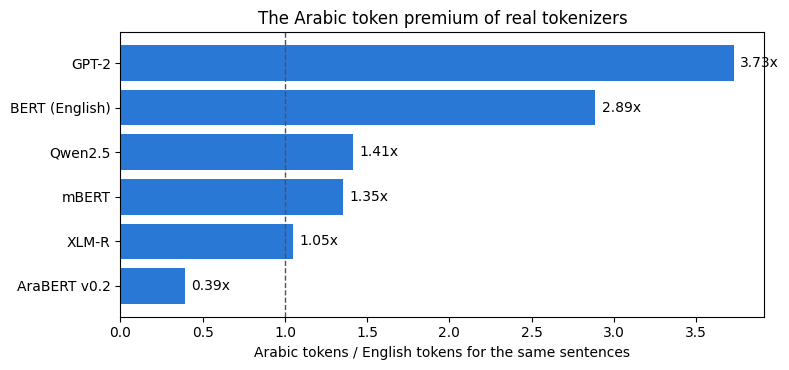

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(real.index, real["premium AR/EN"], color="#2a78d6")
ax.axvline(1.0, color="#52514e", ls="--", lw=1)
for y, v in enumerate(real["premium AR/EN"]):
    ax.text(v + 0.04, y, f"{v:.2f}x", va="center")
ax.set_xlabel("Arabic tokens / English tokens for the same sentences")
ax.set_title("The Arabic token premium of real tokenizers")
plt.tight_layout()
plt.show()

## 4. Train your own BPE tokenizers

Byte-pair encoding starts from single symbols and repeatedly merges the most frequent adjacent pair until the vocabulary reaches a target size. We train **byte-level** BPE, the variant used by GPT-2 and Qwen: its 256 base symbols are bytes, so it can write any text without an unknown token.

Two experiments, both on OPUS-100 training sentences:

1. **Training data:** the same vocabulary size, trained once on English only and once on a mix of English and Arabic.
2. **Vocabulary size:** mixed training data at four vocabulary sizes.

Expected time: about 2 minutes on Colab's CPU (tokenizer training does not use the GPU).

In [14]:
def train_bpe(sentences, vocab_size):
    """A byte-level BPE tokenizer trained on the given sentences."""
    tok = Tokenizer(models.BPE())
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, show_progress=False,
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
    tok.train_from_iterator(sentences, trainer=trainer)
    return tok

def fertility(tok, texts, n_words):
    return sum(len(e.ids) for e in tok.encode_batch(texts)) / n_words

test_en = [p["en"] for p in test_pairs]
test_ar = [p["ar"] for p in test_pairs]

start = time.time()
mid_size = 16_000
english_only = train_bpe(train_en, mid_size)
mixed = train_bpe(train_en + train_ar, mid_size)
data_rows = []
for name, tok in [("English only", english_only), ("English + Arabic", mixed)]:
    data_rows.append({"trained on": name, "fertility EN": fertility(tok, test_en, en_words),
                      "fertility AR": fertility(tok, test_ar, ar_words)})
print(f"Trained two {mid_size:,}-token tokenizers in {time.time() - start:.0f}s")
pd.DataFrame(data_rows).set_index("trained on").round(2)

Trained two 16,000-token tokenizers in 7s


,fertility EN,fertility AR
trained on,,
English only,1.33,9.95
English + Arabic,1.43,1.64


The same Arabic sentence through both tokenizers shows where the difference comes from.

In [15]:
sentence = "ذهبت الطالبات إلى المكتبة لدراسة الذكاء الاصطناعي"
for name, tok in [("English only", english_only), ("English + Arabic", mixed)]:
    ids = tok.encode(sentence).ids
    print(f"{name:17s} {len(ids):3d} tokens: {[tok.decode([i]) for i in ids][:16]}")

English only       92 tokens: ['�', '�', '�', '�', '�', '�', '�', '�', ' ', '�', '�', '�', '�', '�', '�', '�']
English + Arabic   15 tokens: ['ذهبت', ' الط', 'البات', ' إلى', ' المكتب', 'ة', ' ل', 'دراسة', ' الذ', 'كاء', ' ال', 'اص', 'ط', 'نا', 'عي']


Now the vocabulary-size sweep on the mixed training data.

In [16]:
start = time.time()
sweep = []
for v in VOCAB_SIZES:
    tok = train_bpe(train_en + train_ar, v)
    sweep.append({"vocabulary": v, "fertility EN": fertility(tok, test_en, en_words),
                  "fertility AR": fertility(tok, test_ar, ar_words)})
    print(f"vocabulary {v:>6,}: done ({time.time() - start:.0f}s elapsed)")
sweep = pd.DataFrame(sweep).set_index("vocabulary")
sweep.round(2)

vocabulary  1,000: done (4s elapsed)
vocabulary  4,000: done (7s elapsed)
vocabulary 16,000: done (12s elapsed)
vocabulary 32,000: done (16s elapsed)


,fertility EN,fertility AR
vocabulary,,
1000,2.48,2.99
4000,1.78,2.16
16000,1.43,1.64
32000,1.34,1.49


Plot both languages against the vocabulary size (on a log axis, since the sizes grow by factors).

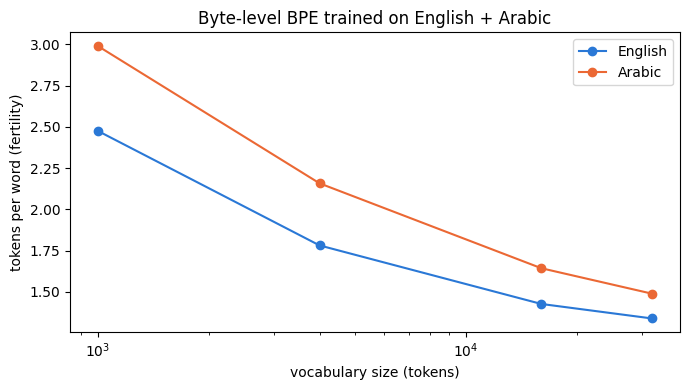

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep.index, sweep["fertility EN"], marker="o", color="#2a78d6", label="English")
ax.plot(sweep.index, sweep["fertility AR"], marker="o", color="#eb6834", label="Arabic")
ax.set_xscale("log")
ax.set_xlabel("vocabulary size (tokens)")
ax.set_ylabel("tokens per word (fertility)")
ax.set_title("Byte-level BPE trained on English + Arabic")
ax.legend()
plt.tight_layout()
plt.show()

**What to notice**

The tokenizer trained on English only writes Arabic byte by byte, about two tokens per letter, and does even worse than GPT-2: the Arabic premium comes from the training data, not from the Arabic language. Adding Arabic to the training data brings Arabic fertility down at the same vocabulary size. In the sweep, fertility falls quickly at first and then flattens: each doubling of the vocabulary buys fewer tokens saved, while the embedding table, which needs one row per token, keeps growing.

## 5. What a document costs

A document's token count sets what it costs on a per-token service, how long a model takes to read it, and what share of a context window it fills. We take the Arabic side of the first 200 test pairs as one document and count it with each real tokenizer.

In [18]:
document_ar = "\n".join(test_ar[:200])
document_en = "\n".join(test_en[:200])
CONTEXT_WINDOW = 4_096
cost = []
for name, tok in toks.items():
    n_ar = count_tokens(tok, [document_ar])
    n_en = count_tokens(tok, [document_en])
    cost.append({"tokenizer": name, "English tokens": n_en, "Arabic tokens": n_ar,
                 f"Arabic share of a {CONTEXT_WINDOW:,}-token window": n_ar / CONTEXT_WINDOW})
pd.DataFrame(cost).set_index("tokenizer").round(2)

,English tokens,Arabic tokens,"Arabic share of a 4,096-token window"
tokenizer,,,
GPT-2,3775,13625,3.33
BERT (English),3652,10566,2.58
mBERT,3873,5348,1.31
XLM-R,3966,4222,1.03
AraBERT v0.2,7803,2987,0.73
Qwen2.5,3649,5323,1.30


## Summary

- The output shape of a task (a label, a label per token, a span, new text) decides which model head, pipeline and metric to use.
- Extractive QA predicts start and end scores and can only copy from the passage; translation writes new text and needs a reference-based metric such as chrF.
- The same content can cost several times more tokens in Arabic than in English, depending only on the tokenizer.
- The premium comes from the tokenizer's training data: adding Arabic to it lowers Arabic fertility at the same vocabulary size.
- Larger vocabularies shorten sequences with diminishing returns, while the embedding table grows with every token added.

## Exercises

1. **Dialects.** Translate three of the Arabic reviews in section 2.1 into a dialect you know (or use Arabizi, Arabic written in Latin letters) and run the Arabic classifier again. Which predictions change, and why might they?
2. **Question answering with no answer.** Ask `answer_span` a question that the passage does not answer. What does it return, and what would a system need in order to say "not in the passage"?
3. **Prompting the LLM.** Change the translation instruction in `translate_llm` (for example, ask for Modern Standard Arabic and a formal register) and compare the chrF score and the examples with the original prompt.
4. **Training data share.** Train a 16,000-token tokenizer on all the English sentences plus only a quarter of the Arabic ones. Where does Arabic fertility land between the two tokenizers of section 4?

## Further Reading

- [Petrov et al., 2023. Language Model Tokenizers Introduce Unfairness Between Languages](https://arxiv.org/abs/2305.15425)
- [Rust et al., 2021. How Good is Your Tokenizer? On the Monolingual Performance of Multilingual Language Models](https://arxiv.org/abs/2012.15613)
- [Sennrich et al., 2016. Neural Machine Translation of Rare Words with Subword Units](https://arxiv.org/abs/1508.07909)
- [Zhang et al., 2020. Improving Massively Multilingual Neural Machine Translation and Zero-Shot Translation (OPUS-100)](https://arxiv.org/abs/2004.11867)
- [Popović, 2015. chrF: character n-gram F-score for automatic MT evaluation](https://aclanthology.org/W15-3049/)
- [Obeid et al., 2020. CAMeL Tools: An Open Source Python Toolkit for Arabic Natural Language Processing](https://aclanthology.org/2020.lrec-1.868/)

### Contributed by: Yazan Alshoibi